# Vehicle Fuel Consumption Analysis
**Course:** EDAV (22ADC32N) – Course-End Project

## Objective
To analyse real vehicle fuel economy data (EPA-style records of 38,113 vehicles, model years 1984–2017) using NumPy, Pandas and Matplotlib. The project covers statistical summaries, grouped analysis, data-quality checks, descriptive statistics by driving condition, visualizations and a trip fuel estimate.

## 1. Environment Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 100

## 2. Dataset Preparation
The dataset (`fuel.csv`) contains only the columns required for this analysis: vehicle identity (year, make, model, class), configuration (drive, transmission, cylinders, engine displacement, fuel type) and fuel economy / cost / emission measures.

In [ ]:
df = pd.read_csv("fuel.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (38113, 15)


   year        make               model                        class          drive       transmission  engine_cylinders  engine_displacement fuel_type  city_mpg_ft1  highway_mpg_ft1  \
0  1984  Alfa Romeo           GT V6 2.5             Minicompact Cars            NaN     Manual 5-Speed               6.0                  2.5   Regular            17               24   
1  1984  Alfa Romeo           GT V6 2.5             Minicompact Cars            NaN     Manual 5-Speed               6.0                  2.5   Regular            17               24   
2  1984  Alfa Romeo  Spider Veloce 2000                  Two Seaters            NaN     Manual 5-Speed               4.0                  2.0   Regular            18               25   
3  1984  Alfa Romeo  Spider Veloce 2000                  Two Seaters            NaN     Manual 5-Speed               4.0                  2.0   Regular            18               25   
4  1984  AM General   DJ Po Vehicle 2WD  Special Purpose Vehicle 2WD  

## 3. Initial Inspection and Cleaning

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38113 entries, 0 to 38112
Data columns (total 15 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   year                               38113 non-null  int64  
 1   make                               38113 non-null  str    
 2   model                              38113 non-null  str    
 3   class                              38113 non-null  str    
 4   drive                              36924 non-null  str    
 5   transmission                       38102 non-null  str    
 6   engine_cylinders                   37977 non-null  float64
 7   engine_displacement                37979 non-null  float64
 8   fuel_type                          38113 non-null  str    
 9   city_mpg_ft1                       38113 non-null  int64  
 10  highway_mpg_ft1                    38113 non-null  int64  
 11  combined_mpg_ft1                   38113 non-null  int64  
 12  a

In [ ]:
df.describe()

               year  engine_cylinders  engine_displacement  city_mpg_ft1  highway_mpg_ft1  combined_mpg_ft1  annual_fuel_cost_ft1  tailpipe_co2_in_grams_mile_ft1  annual_consumption_in_barrels_ft1
count  38113.000000      37977.000000         37979.000000  38113.000000     38113.000000      38113.000000          38113.000000                    38113.000000                       38113.000000
mean    2000.194527          5.736656             3.317583     17.981109        24.080786         20.216068           1970.675360                      472.761382                          17.517635
std       10.464573          1.752254             1.361995      6.849728         7.026649          6.772655            532.555234                      122.200358                           4.577019
min     1984.000000          2.000000             0.000000      6.000000         9.000000          7.000000            500.000000                        0.000000                           0.060000
25%     1991.00

**Cleaning steps:** remove duplicate rows, rename columns to readable names, group the detailed vehicle class and fuel type into broader categories, and handle missing values. Missing engine size / cylinders belong to purely electric vehicles (no combustion engine), so they are set to 0; the few remaining gaps are filled with the median of engine vehicles, and missing text values with `Unknown`.

In [ ]:
df_clean = df.copy().drop_duplicates()

df_clean = df_clean.rename(columns={
    "year": "Year", "make": "Make", "model": "Model", "class": "Class",
    "drive": "Drive", "transmission": "Transmission",
    "engine_cylinders": "Cylinders", "engine_displacement": "Engine_Displacement_L",
    "fuel_type": "Fuel_Type", "city_mpg_ft1": "City_MPG",
    "highway_mpg_ft1": "Highway_MPG", "combined_mpg_ft1": "Combined_MPG",
    "annual_fuel_cost_ft1": "Annual_Fuel_Cost_USD",
    "tailpipe_co2_in_grams_mile_ft1": "CO2_g_per_mile",
    "annual_consumption_in_barrels_ft1": "Annual_Barrels",
})

def vehicle_group(c):
    if "Pickup" in c: return "Pickup Trucks"
    if "Sport Utility" in c: return "SUVs"
    if "Minivan" in c: return "Minivans"
    if "Van" in c: return "Vans"
    if "Station Wagon" in c: return "Station Wagons"
    if "Two Seaters" in c: return "Two Seaters"
    if "Special Purpose" in c: return "Special Purpose"
    return "Cars"

def fuel_group(f):
    if "Electricity" in f: return "Electricity-based"
    if "Diesel" in f: return "Diesel"
    if "Premium" in f: return "Premium"
    if "Regular" in f: return "Regular"
    return "Other"

df_clean["Vehicle_Group"] = df_clean["Class"].apply(vehicle_group)
df_clean["Fuel_Group"] = df_clean["Fuel_Type"].apply(fuel_group)

missing_report = df_clean.isna().sum()
missing_report = missing_report[missing_report > 0].to_frame("Missing_Values")
missing_report["Missing_%"] = (missing_report["Missing_Values"] / len(df_clean) * 100).round(2)

is_electric = df_clean["Fuel_Type"] == "Electricity"
for col in ["Cylinders", "Engine_Displacement_L"]:
    df_clean.loc[is_electric & df_clean[col].isna(), col] = 0
    df_clean[col] = df_clean[col].fillna(df_clean.loc[df_clean[col] > 0, col].median())
for col in ["Drive", "Transmission"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

print("Rows before cleaning:", len(df), "| Rows after cleaning:", len(df_clean))
print("Missing values left:", int(df_clean.isna().sum().sum()))
df_clean.head()

Rows before cleaning: 38113 | Rows after cleaning: 37226
Missing values left: 0


   Year                         Make               Model                        Class                       Drive       Transmission  Cylinders  Engine_Displacement_L Fuel_Type  City_MPG  \
0  1984                   Alfa Romeo           GT V6 2.5             Minicompact Cars                     Unknown     Manual 5-Speed        6.0                    2.5   Regular        17   
2  1984                   Alfa Romeo  Spider Veloce 2000                  Two Seaters                     Unknown     Manual 5-Speed        4.0                    2.0   Regular        18   
4  1984                   AM General   DJ Po Vehicle 2WD  Special Purpose Vehicle 2WD               2-Wheel Drive  Automatic 3-Speed        4.0                    2.5   Regular        18   
6  1984                   AM General    FJ8c Post Office  Special Purpose Vehicle 2WD               2-Wheel Drive  Automatic 3-Speed        6.0                    4.2   Regular        13   
8  1984  American Motors Corporation           Eag

**Conclusion:** The raw data had 38,113 rows and 15 columns; 887 duplicate rows were removed, leaving 37,226 vehicles. Missing values were found in Drive (887), Transmission (11), Cylinders (136) and Engine Displacement (135). Almost all missing engine values belong to purely electric vehicles, which have no engine, so they were set to 0 rather than given a misleading median. After cleaning, no missing values remain.

## Q1. NumPy Statistical Analysis  [CO1, BL3]
Basic statistics of the fuel economy and cost measures using NumPy arrays.

In [ ]:
measures = ["City_MPG", "Highway_MPG", "Combined_MPG", "Annual_Fuel_Cost_USD", "CO2_g_per_mile"]
rows = []
for col in measures:
    arr = df_clean[col].to_numpy()
    rows.append({
        "Measure": col,
        "Mean": np.mean(arr), "Median": np.median(arr), "Std_Dev": np.std(arr),
        "Min": np.min(arr), "Max": np.max(arr),
        "Q1": np.percentile(arr, 25), "Q3": np.percentile(arr, 75),
    })
numpy_stats = pd.DataFrame(rows).set_index("Measure").round(2)
numpy_stats

                         Mean   Median  Std_Dev    Min      Max      Q1       Q3
Measure                                                                         
City_MPG                17.99    17.00     6.90    6.0   150.00    15.0    20.00
Highway_MPG             24.11    24.00     7.05    9.0   122.00    20.0    27.00
Combined_MPG            20.23    19.00     6.81    7.0   136.00    17.0    23.00
Annual_Fuel_Cost_USD  1970.97  1950.00   532.04  500.0  6050.00  1600.0  2350.00
CO2_g_per_mile         472.37   467.74   121.83    0.0  1269.57   387.0   555.44

In [ ]:
mpg = df_clean["Combined_MPG"].to_numpy()
print("Average combined MPG:", round(np.mean(mpg), 2))
print("Best combined MPG   :", np.max(mpg))
print("Worst combined MPG  :", np.min(mpg))
print("Vehicles above average MPG:", int(np.sum(mpg > np.mean(mpg))), "of", len(mpg))

Average combined MPG: 20.23
Best combined MPG   : 136
Worst combined MPG  : 7
Vehicles above average MPG: 15248 of 37226


**Conclusion:** The average combined fuel economy is 20.23 MPG (median 19 MPG), with a standard deviation of 6.81. Values range from 7 to 136 MPG, and 15,248 of 37,226 vehicles are above the average. The very high maximum values come from electric vehicles, which are measured in MPG-equivalent. Mean annual fuel cost is about $1,971.

## Q2. Pandas Group-By Analysis  [CO2, BL4]
Vehicles are grouped by broad vehicle group and by fuel group.

In [ ]:
group_summary = df_clean.groupby("Vehicle_Group").agg(
    Vehicles=("Make", "size"),
    Mean_City_MPG=("City_MPG", "mean"),
    Mean_Highway_MPG=("Highway_MPG", "mean"),
    Mean_Combined_MPG=("Combined_MPG", "mean"),
    Mean_Annual_Fuel_Cost=("Annual_Fuel_Cost_USD", "mean"),
    Mean_CO2_g_per_mile=("CO2_g_per_mile", "mean"),
).round(2).sort_values("Mean_Combined_MPG", ascending=False)
group_summary

                 Vehicles  Mean_City_MPG  Mean_Highway_MPG  Mean_Combined_MPG  Mean_Annual_Fuel_Cost  Mean_CO2_g_per_mile
Vehicle_Group                                                                                                            
Station Wagons       2607          20.07             26.76              22.54                1700.82               409.42
Cars                17461          19.80             27.08              22.45                1812.89               421.64
Two Seaters          1835          17.71             24.35              20.09                2280.44               493.37
SUVs                 5241          17.15             22.47              19.12                2013.45               487.86
Minivans              384          16.69             23.26              19.07                1865.49               469.81
Special Purpose      2257          15.51             19.56              17.04                2169.89               546.69
Pickup Trucks        558

In [ ]:
fuel_summary = df_clean.groupby("Fuel_Group").agg(
    Vehicles=("Make", "size"),
    Mean_Combined_MPG=("Combined_MPG", "mean"),
    Mean_Annual_Fuel_Cost=("Annual_Fuel_Cost_USD", "mean"),
    Mean_CO2_g_per_mile=("CO2_g_per_mile", "mean"),
).round(2).sort_values("Mean_Combined_MPG", ascending=False)
fuel_summary

                   Vehicles  Mean_Combined_MPG  Mean_Annual_Fuel_Cost  Mean_CO2_g_per_mile
Fuel_Group                                                                                
Electricity-based       198              73.10                 950.25                53.35
Diesel                  958              23.40                1784.60               470.59
Regular               24518              20.19                1849.30               469.50
Premium               10172              19.36                2285.46               480.53
Other                  1380              17.56                2090.43               524.73

**Conclusion:** Station Wagons (22.54 MPG) and Cars (22.45 MPG) are the most efficient groups, while Vans (14.75 MPG) and Pickup Trucks (16.51 MPG) are the least efficient and also have the highest annual fuel cost and CO2 emissions. Electricity-based vehicles average 73.10 MPG and about $950 annual fuel cost, while Premium fuel vehicles have the highest annual cost ($2,285) among conventional fuels.

## Q3. Missing Values and Anomaly Detection  [CO3, BL3]
Missing values found in the raw data, validity checks, and outliers detected with the IQR method.

In [ ]:
print("Missing values found before filling:")
missing_report

Missing values found before filling:


                       Missing_Values  Missing_%
Drive                             887       2.38
Transmission                       11       0.03
Cylinders                         136       0.37
Engine_Displacement_L             134       0.36

In [ ]:
print("Invalid (non-positive) values after cleaning:")
for col in ["City_MPG", "Highway_MPG", "Combined_MPG", "Annual_Fuel_Cost_USD"]:
    print(f"  {col}: {int((df_clean[col] <= 0).sum())}")
non_electric = df_clean[df_clean["Fuel_Type"] != "Electricity"]
print("  Engine_Displacement_L (non-electric vehicles):", int((non_electric["Engine_Displacement_L"] <= 0).sum()))
print("Duplicate rows removed:", len(df) - len(df_clean))

Invalid (non-positive) values after cleaning:
  City_MPG: 0
  Highway_MPG: 0
  Combined_MPG: 0
  Annual_Fuel_Cost_USD: 0
  Engine_Displacement_L (non-electric vehicles): 0
Duplicate rows removed: 887


In [ ]:
outlier_rows = []
for col in ["City_MPG", "Highway_MPG", "Combined_MPG", "Annual_Fuel_Cost_USD", "CO2_g_per_mile"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df_clean[col] < lower) | (df_clean[col] > upper)).sum())
    outlier_rows.append({"Column": col, "Lower_Bound": round(lower, 2), "Upper_Bound": round(upper, 2),
                         "Outliers": n_out, "Outlier_%": round(n_out / len(df_clean) * 100, 2)})
outlier_summary = pd.DataFrame(outlier_rows).set_index("Column")
outlier_summary

                      Lower_Bound  Upper_Bound  Outliers  Outlier_%
Column                                                             
City_MPG                     7.50        27.50      1418       3.81
Highway_MPG                  9.50        37.50       875       2.35
Combined_MPG                 8.00        32.00       904       2.43
Annual_Fuel_Cost_USD       475.00      3475.00       582       1.56
CO2_g_per_mile             134.34       808.09       370       0.99

In [ ]:
mpg_upper = outlier_summary.loc["Combined_MPG", "Upper_Bound"]
high_mpg = df_clean[df_clean["Combined_MPG"] > mpg_upper]
print("High-MPG outliers by fuel group:")
print(high_mpg["Fuel_Group"].value_counts())

High-MPG outliers by fuel group:
Fuel_Group
Regular              531
Electricity-based    167
Diesel               166
Premium               35
Name: count, dtype: int64


**Conclusion:** No invalid (zero or negative) MPG, cost or engine values remain after cleaning. The IQR method flags 904 combined-MPG outliers (2.43%), all above the upper bound of 32 MPG; 167 of them are electricity-based vehicles and the rest are mostly efficient Regular and Diesel vehicles. These are real values, not errors, so they were kept.

## Q4. Descriptive Statistics by Driving Condition  [CO4, BL4]
City, highway and combined driving are the three driving conditions in the dataset.

In [ ]:
conditions = ["City_MPG", "Highway_MPG", "Combined_MPG"]
condition_stats = df_clean[conditions].agg(["count", "mean", "median", "min", "max", "std"]).T.round(2)
condition_stats

                count   mean  median  min    max   std
City_MPG      37226.0  17.99    17.0  6.0  150.0  6.90
Highway_MPG   37226.0  24.11    24.0  9.0  122.0  7.05
Combined_MPG  37226.0  20.23    19.0  7.0  136.0  6.81

In [ ]:
median_by_group = df_clean.groupby("Vehicle_Group")[conditions].median().round(1)
median_by_group["Highway_minus_City"] = median_by_group["Highway_MPG"] - median_by_group["City_MPG"]
median_by_group.sort_values("Combined_MPG", ascending=False)

                 City_MPG  Highway_MPG  Combined_MPG  Highway_minus_City
Vehicle_Group                                                           
Station Wagons       19.0         26.0          22.0                 7.0
Cars                 18.0         26.0          21.0                 8.0
Two Seaters          16.0         23.0          19.0                 7.0
Minivans             16.0         23.0          19.0                 7.0
SUVs                 16.0         22.0          18.0                 6.0
Special Purpose      15.0         20.0          17.0                 5.0
Pickup Trucks        15.0         19.0          16.0                 4.0
Vans                 13.0         17.0          14.0                 4.0

**Conclusion:** Highway driving gives better fuel economy than city driving: mean 24.11 MPG on the highway against 17.99 MPG in the city, with combined driving in between at 20.23 MPG. City MPG varies a little less than highway MPG (std 6.90 vs 7.05). The highway advantage is largest for Cars (8 MPG) and smallest for Pickup Trucks and Vans (4 MPG).

## Q5. Data Visualizations  [CO5, BL5]

### Chart 1: Average City vs Highway MPG by Vehicle Group

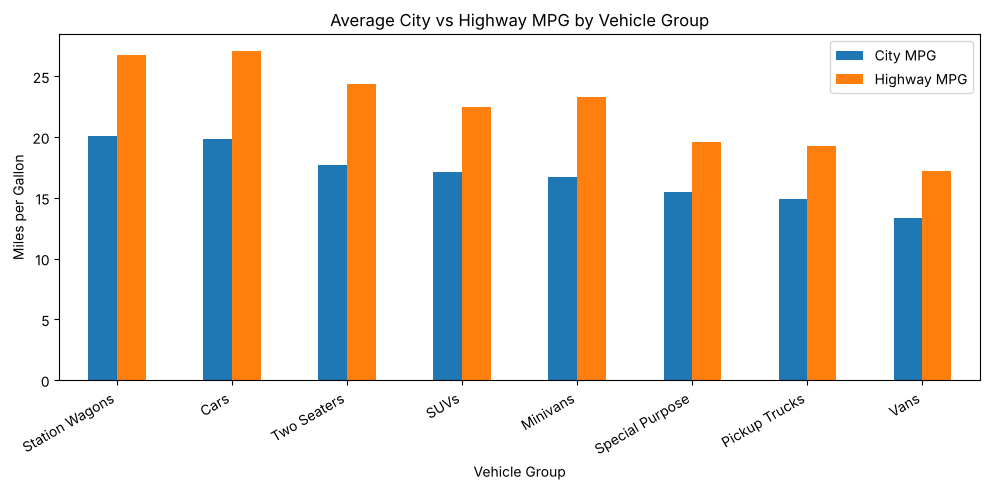

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
group_summary[["Mean_City_MPG", "Mean_Highway_MPG"]].plot(kind="bar", ax=ax, color=["#1f77b4", "#ff7f0e"])
ax.set_title("Average City vs Highway MPG by Vehicle Group")
ax.set_xlabel("Vehicle Group")
ax.set_ylabel("Miles per Gallon")
ax.legend(["City MPG", "Highway MPG"])
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Chart 2: Average Annual Fuel Cost by Vehicle Group

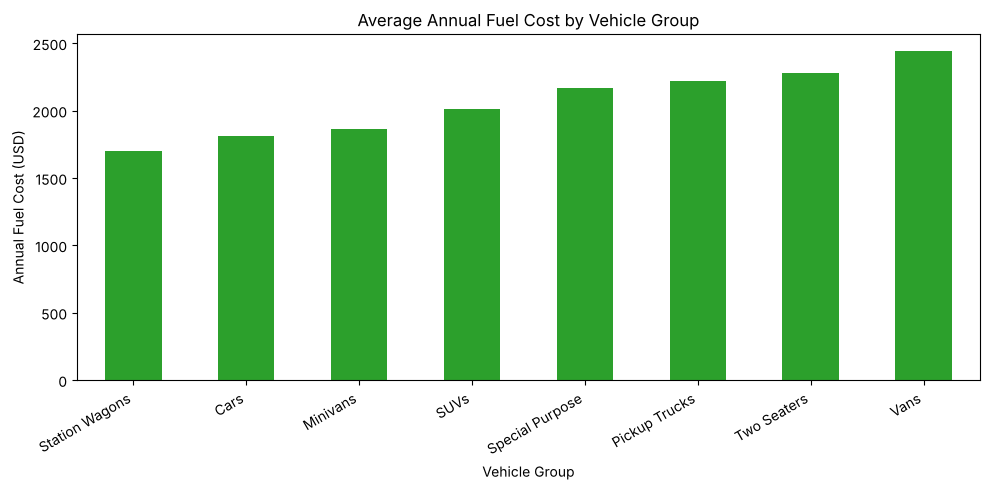

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
group_summary["Mean_Annual_Fuel_Cost"].sort_values().plot(kind="bar", ax=ax, color="#2ca02c")
ax.set_title("Average Annual Fuel Cost by Vehicle Group")
ax.set_xlabel("Vehicle Group")
ax.set_ylabel("Annual Fuel Cost (USD)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Chart 3: Engine Displacement vs Combined MPG

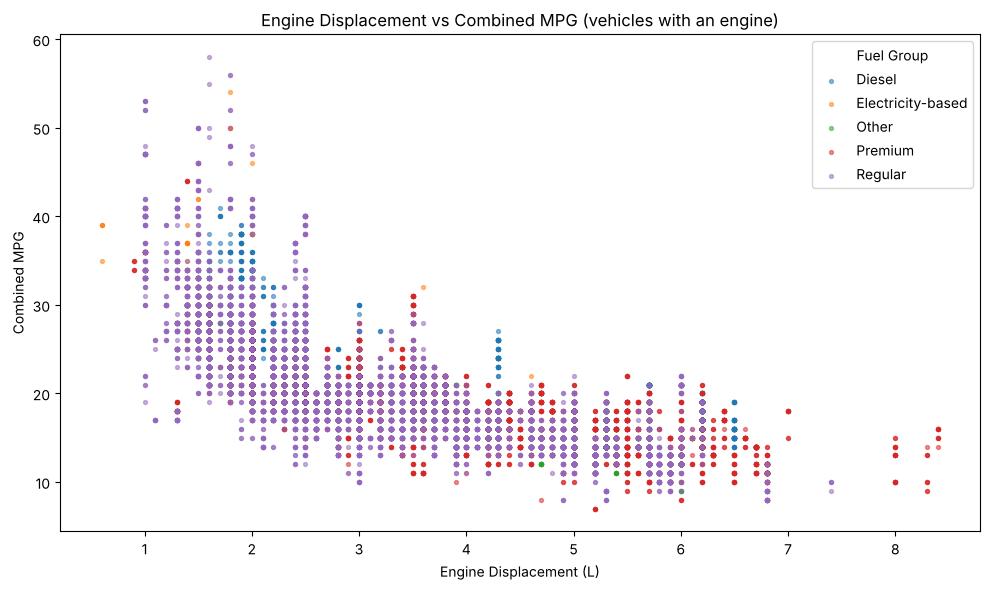

In [ ]:
engine_df = df_clean[df_clean["Engine_Displacement_L"] > 0]   # vehicles with a combustion engine

fig, ax = plt.subplots(figsize=(10, 6))
for fuel, part in engine_df.groupby("Fuel_Group"):
    ax.scatter(part["Engine_Displacement_L"], part["Combined_MPG"], s=8, alpha=0.5, label=fuel)
ax.set_title("Engine Displacement vs Combined MPG (vehicles with an engine)")
ax.set_xlabel("Engine Displacement (L)")
ax.set_ylabel("Combined MPG")
ax.legend(title="Fuel Group")
plt.tight_layout()
plt.show()

### Chart 4: Correlation Heatmap (vehicles with an engine)

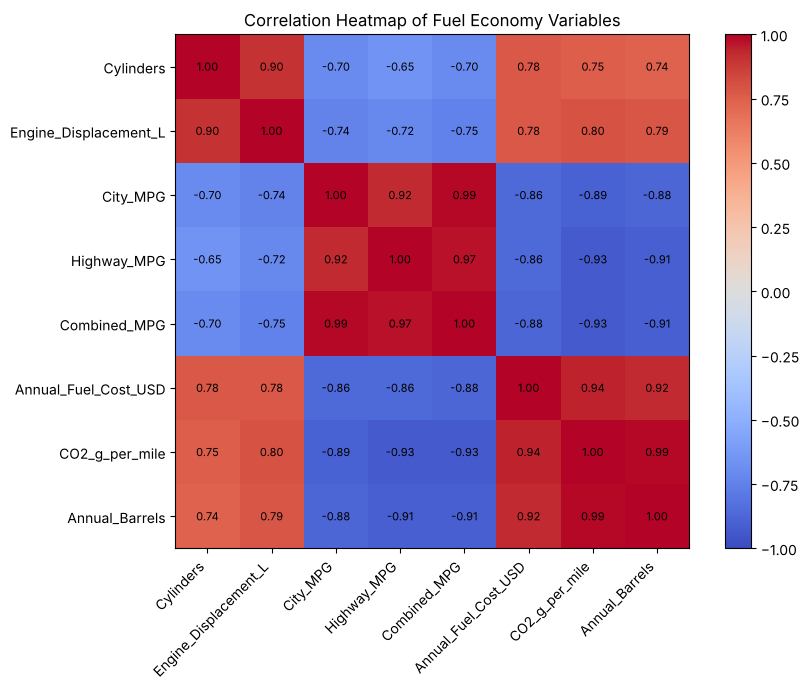

In [ ]:
corr_cols = ["Cylinders", "Engine_Displacement_L", "City_MPG", "Highway_MPG", "Combined_MPG",
             "Annual_Fuel_Cost_USD", "CO2_g_per_mile", "Annual_Barrels"]
corr = engine_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title("Correlation Heatmap of Fuel Economy Variables")
plt.tight_layout()
plt.show()

**Conclusion:** Every vehicle group does better on the highway than in the city, and larger vehicles (Vans, Pickup Trucks) have the highest annual fuel cost. The scatter plot shows combined MPG falling as engine size grows, and the heatmap confirms this: engine displacement and combined MPG have a correlation of -0.75, while combined MPG and CO2 per mile are strongly negatively related (-0.93). Annual fuel cost, CO2 and fuel barrels are closely linked (0.92 or higher).

## Additional Analysis: Trip Fuel Estimate
Fuel needed for a trip, estimated from each vehicle group's median combined MPG. Electricity-based vehicles are excluded because their MPG values are not gasoline-based. Conversions: 1 mile = 1.609 km, 1 US gallon = 3.785 L.

In [ ]:
trip_distance_km = 500
trip_miles = trip_distance_km / 1.609

gas_vehicles = df_clean[df_clean["Fuel_Group"] != "Electricity-based"]
trip_estimate = gas_vehicles.groupby("Vehicle_Group").agg(
    Median_Combined_MPG=("Combined_MPG", "median"),
    Median_CO2_g_per_mile=("CO2_g_per_mile", "median"),
)
trip_estimate["Fuel_Needed_Litres"] = (trip_miles / trip_estimate["Median_Combined_MPG"] * 3.785).round(1)
trip_estimate["CO2_Emitted_kg"] = (trip_miles * trip_estimate["Median_CO2_g_per_mile"] / 1000).round(1)
trip_estimate = trip_estimate.sort_values("Fuel_Needed_Litres")
print(f"Estimated fuel and CO2 for a {trip_distance_km} km trip:")
trip_estimate

Estimated fuel and CO2 for a 500 km trip:


                 Median_Combined_MPG  Median_CO2_g_per_mile  Fuel_Needed_Litres  CO2_Emitted_kg
Vehicle_Group                                                                                  
Station Wagons                  22.0             407.200000                53.5           126.5
Cars                            21.0             423.190476                56.0           131.5
Two Seaters                     19.0             467.736842                61.9           145.4
Minivans                        19.0             467.736842                61.9           145.4
SUVs                            18.0             489.000000                65.3           152.0
Special Purpose                 17.0             522.764706                69.2           162.5
Pickup Trucks                   16.0             555.437500                73.5           172.6
Vans                            14.0             634.785714                84.0           197.3

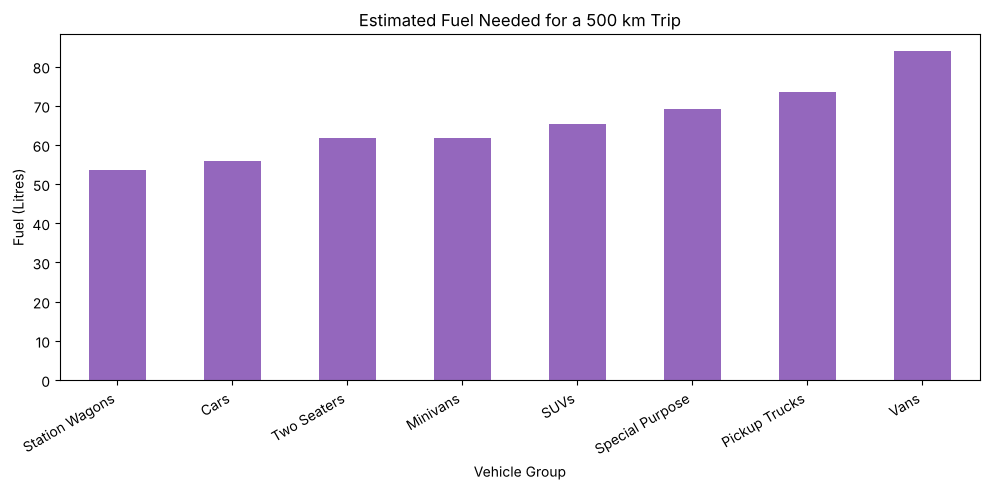

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
trip_estimate["Fuel_Needed_Litres"].plot(kind="bar", ax=ax, color="#9467bd")
ax.set_title(f"Estimated Fuel Needed for a {trip_distance_km} km Trip")
ax.set_xlabel("Vehicle Group")
ax.set_ylabel("Fuel (Litres)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Conclusion:** For a 500 km trip, a Station Wagon needs about 53.5 litres of fuel (126.5 kg CO2), while a Van needs about 84.0 litres (197.3 kg CO2), roughly 57% more fuel. Choosing a more efficient vehicle group clearly reduces both fuel use and emissions.

## Overall Conclusion

**Conclusion:** The analysis of 37,226 vehicles shows that fuel economy depends mainly on vehicle type and engine size. Larger engines and heavier vehicle groups (Vans, Pickup Trucks, Special Purpose) use more fuel, cost more per year and emit more CO2, while Cars and Station Wagons are the most economical conventional options. Highway driving is more efficient than city driving for every group. Electric vehicles are the clear efficiency outliers, and the data had few quality problems (887 duplicates and a small number of missing values). Overall, choosing a smaller engine and an efficient vehicle group is the most effective way to lower fuel cost and emissions.